# PEDIS footprint dataset – exploratory data analysis

This notebook explores the PEDIS podoscope footprint images, the result of the cleaning /
preprocessing step and the labels extracted from the legacy PEDIS database.

Pipeline that produces the inputs of this notebook:

```
python src/parse_pedis_db.py --db <raw>/PEDI3.MDB --images <raw> --out-dir data
python src/make_labels.py --data-dir data
python src/preprocess.py --raw <raw> --data-dir data
```

Questions answered here:

1. What is in the raw data folder and which files are usable images?
2. How are the images encoded, and how do we recover the intensity?
3. What does the cleaning (quality control) remove, and what do the training crops look like?
4. What metadata and condition labels are available, and how balanced are they?
5. Is the train / validation / test split sound?

**Privacy:** the raw folder contains photos of people (RGB files) and the database holds personal
data. This notebook only displays footprint images and aggregated statistics.

In [1]:
from pathlib import Path
import collections
import os
import random
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Repository root = parent of the notebooks/ folder.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import preprocess as pp  # noqa: E402  (decoding and QC thresholds live there)

DATA_DIR = ROOT / "data"
FEET_DIR = DATA_DIR / "processed" / "feet"
# The raw folder name contains accented characters; glob avoids Unicode normalisation issues.
RAW_DIR = Path(os.environ["PEDIS_DIR"]) if "PEDIS_DIR" in os.environ else next(ROOT.glob("PEDIS*")) / "PEDIS"

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
random.seed(0)
print("raw images:", RAW_DIR.exists(), "| labels:", (DATA_DIR / "labels.csv").exists(),
      "| preprocessed:", (DATA_DIR / "processed" / "feet.csv").exists())

raw images: True | labels: True | preprocessed: True


## 1. Raw folder inventory

In [2]:
files = [p for p in RAW_DIR.iterdir() if p.is_file()]
ext_counts = collections.Counter(p.suffix.lower() or "(none)" for p in files)
prefix_counts = collections.Counter(p.stem[:2].upper() for p in files if p.suffix.lower() == ".bmp")
print(f"{len(files)} files in {RAW_DIR.name}/")
print(pd.Series(ext_counts).sort_values(ascending=False).to_string())
print("\nBMP file name prefixes:", dict(prefix_counts.most_common()))

44587 files in PEDIS/
.bmp      44455
.jpg         72
.tif         18
.rpt         10
.dll          9
.exe          6
.mdb          4
.cfg          2
.log          2
.png          1
.pdf          1
.wav          1
.000          1
.txt          1
.001          1
.002          1
.rtf          1
(none)        1

BMP file name prefixes: {'AK': 43870, 'SP': 563, 'SJ': 15, 'TE': 3, 'SA': 2, 'GA': 1, 'Q': 1}


Almost everything is a `.bmp` footprint image named `AKxxxxxx` (plus a smaller `SPxxxxxx` series).
The remaining files belong to the original Windows application (executables, DLLs, reports,
Access databases). Only `PEDI3.MDB` is used from these, because it holds the patient records.

## 2. Image encoding

In [3]:
bmp_files = sorted(p for p in files if p.suffix.lower() == ".bmp")
formats, unreadable = collections.Counter(), 0
for p in bmp_files:
    try:
        with Image.open(p) as im:
            formats[(im.size, im.mode)] += 1
    except Exception:
        unreadable += 1
fmt = pd.DataFrame([(f"{w}x{h}", mode, n) for ((w, h), mode), n in formats.items()],
                   columns=["size", "mode", "images"]).sort_values("images", ascending=False)
print(f"{len(bmp_files)} BMP files, {unreadable} unreadable (fragments left over from data recovery)")
fmt.reset_index(drop=True)

44455 BMP files, 41 unreadable (fragments left over from data recovery)


,size,mode,images
0,320x240,P,36421
1,352x288,P,7682
2,320x240,RGB,138
3,640x480,P,110
4,397x253,RGB,52
5,352x288,RGB,7
6,800x600,RGB,1
7,640x480,RGB,1
8,577x360,P,1
9,320x240,L,1


About 99% of the files are **8-bit palette (`P`) images** of 320×240 or 352×288 pixels. The RGB
files are photos or screenshots (some show people), so they are dropped.

### The palette index is *not* the intensity

The podoscope camera image was shown by the PEDIS software in a **16-colour false-colour scale**.
When the images were saved, the colours were re-quantised into arbitrary palette slots. Neighbouring
indices therefore do not mean neighbouring intensities. Displaying the raw index as a grey image
gives banded noise. The intensity is recovered by mapping each pixel's **colour** back to its
position on the scale (`preprocess.decode`).

990/994 sampled palette images use only the 16 scale colours


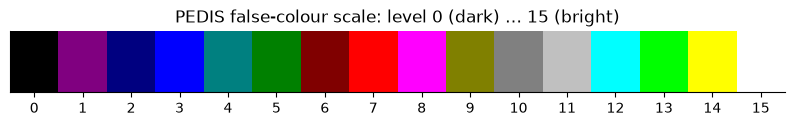

In [4]:
fig, ax = plt.subplots(figsize=(10, 0.8))
ax.imshow(np.array(pp.FALSE_COLOUR_SCALE, dtype=np.uint8)[None], aspect="auto")
ax.set_yticks([])
ax.set_xticks(range(16))
ax.set_title("PEDIS false-colour scale: level 0 (dark) … 15 (bright)")

palette_images = [p for p in bmp_files if p.stem[:2].upper() == "AK"]
covered, sampled = 0, 0
for p in random.sample(palette_images, 1000):
    try:
        with Image.open(p) as im:
            if im.mode != "P":
                continue
            rgb = np.asarray(im.convert("RGB")).reshape(-1, 3)
    except Exception:
        continue
    keys = rgb[:, 0].astype(np.int32) << 16 | rgb[:, 1].astype(np.int32) << 8 | rgb[:, 2]
    sampled += 1
    covered += all(int(k) in pp.COLOUR_TO_LEVEL for k in np.unique(keys))
print(f"{covered}/{sampled} sampled palette images use only the 16 scale colours")

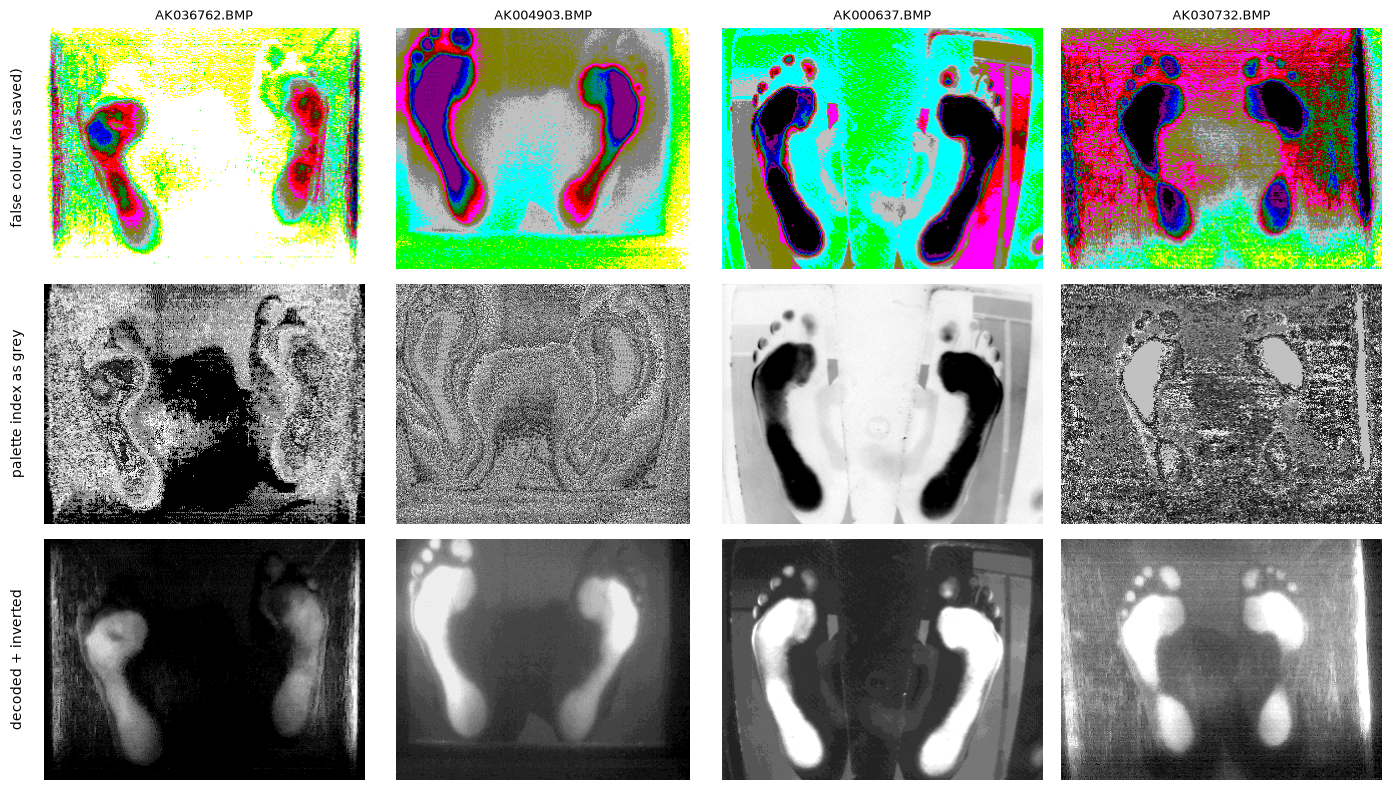

In [5]:
examples = random.sample(palette_images, 4)
fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for col, p in enumerate(examples):
    with Image.open(p) as im:
        axes[0, col].imshow(im.convert("RGB"))
        axes[1, col].imshow(np.asarray(im), cmap="gray")
    axes[2, col].imshow(pp.decode(p), cmap="gray", vmin=0, vmax=1)
    axes[0, col].set_title(p.name, fontsize=9)
for row, label in enumerate(["false colour (as saved)", "palette index as grey", "decoded + inverted"]):
    axes[row, 0].text(-0.06, 0.5, label, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()

After decoding, the image is inverted so that the sole (dark on the podoscope glass) is **bright on a
dark background**. Within the sole, brighter means stronger contact.

## 3. Cleaning and preprocessing (`src/preprocess.py`)

For every image the two feet are separated at the darkest column between them. Each foot is located
with a thresholded mask (the main blob, plus blobs in the same column such as toes or a detached
heel). The foot is cropped with a fixed-aspect window of full image height, the foot on the left of
the image is mirrored, and the crop is resized to 96×224 px. Quality control marks a crop as bad if:

* the image is **overexposed** (the top/bottom rows are bright: the platform, not the background),
* the image has **no contrast**,
* the image is **rough**: it was rendered with another colour scale and decodes into banded noise,
* the **foot blob** is too short, has an implausible aspect ratio, or fills too little of its box.

In [6]:
feet = pd.read_csv(DATA_DIR / "processed" / "feet.csv")
dropped = pd.read_csv(DATA_DIR / "processed" / "dropped_images.csv")
print(f"raw BMP images: {len(bmp_files)} | dropped before cropping: {len(dropped)} "
      f"| foot crops: {len(feet)} | passing QC: {feet.qc_ok.sum()} ({feet.qc_ok.mean():.1%})")

reasons = {
    "overexposed": feet.border_brightness > pp.MAX_BORDER_BRIGHTNESS,
    "low contrast": feet.contrast < pp.MIN_CONTRAST,
    "banded noise": feet.roughness > pp.MAX_ROUGHNESS,
    "foot too short": feet.foot_height < pp.MIN_FOOT_HEIGHT,
    "odd foot shape": ~feet.foot_aspect.between(*pp.FOOT_ASPECT_RANGE) | (feet.foot_fill < pp.MIN_FILL),
}
pd.DataFrame({"crops": {k: int(v.sum()) for k, v in reasons.items()},
              "share": {k: f"{v.mean():.1%}" for k, v in reasons.items()}})

raw BMP images: 44455 | dropped before cropping: 240 | foot crops: 88430 | passing QC: 76575.0 (86.6%)


,crops,share
overexposed,7838,8.9%
low contrast,42,0.0%
banded noise,652,0.7%
foot too short,1765,2.0%
odd foot shape,6322,7.1%


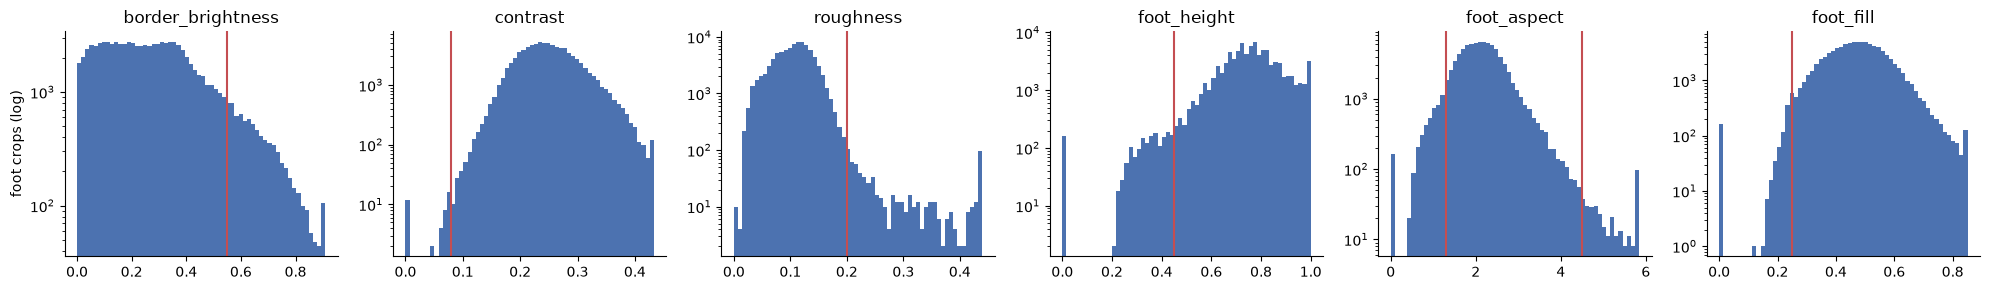

In [7]:
metrics = [("border_brightness", pp.MAX_BORDER_BRIGHTNESS), ("contrast", pp.MIN_CONTRAST),
           ("roughness", pp.MAX_ROUGHNESS), ("foot_height", pp.MIN_FOOT_HEIGHT),
           ("foot_aspect", pp.FOOT_ASPECT_RANGE), ("foot_fill", pp.MIN_FILL)]
fig, axes = plt.subplots(1, len(metrics), figsize=(20, 3))
for ax, (col, limit) in zip(axes, metrics):
    ax.hist(feet[col].clip(upper=feet[col].quantile(0.999)), bins=60, color="#4C72B0")
    for x in np.atleast_1d(limit):
        ax.axvline(x, color="#C44E52", lw=1.5)
    ax.set_title(col)
    ax.set_yscale("log")
axes[0].set_ylabel("foot crops (log)")
plt.tight_layout()

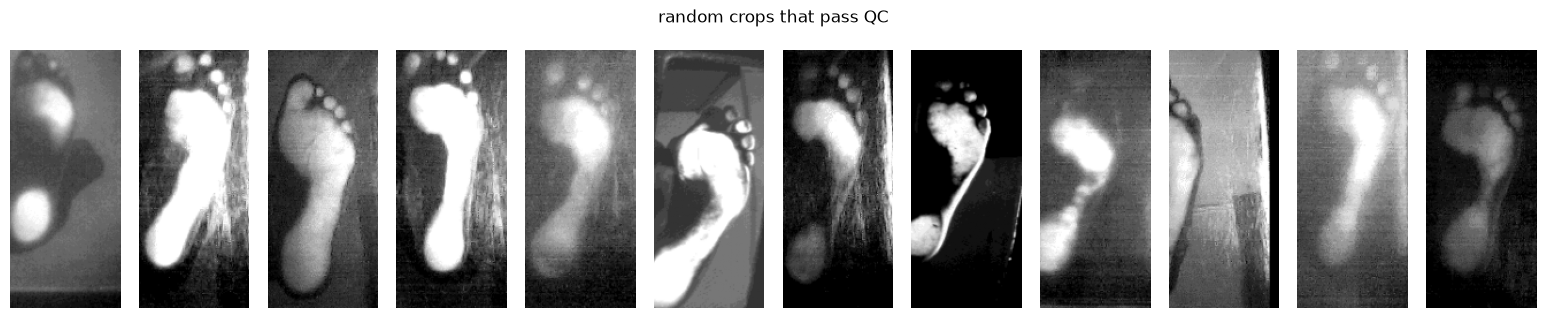

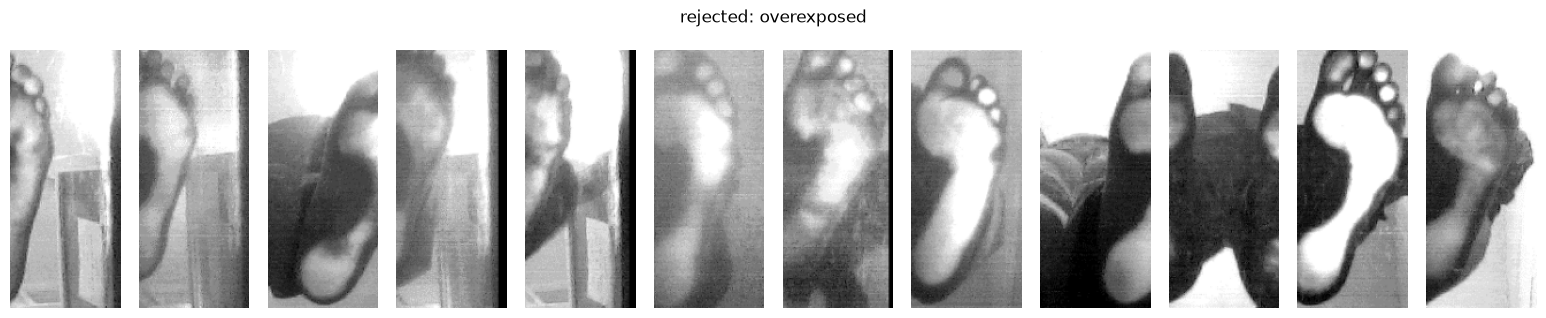

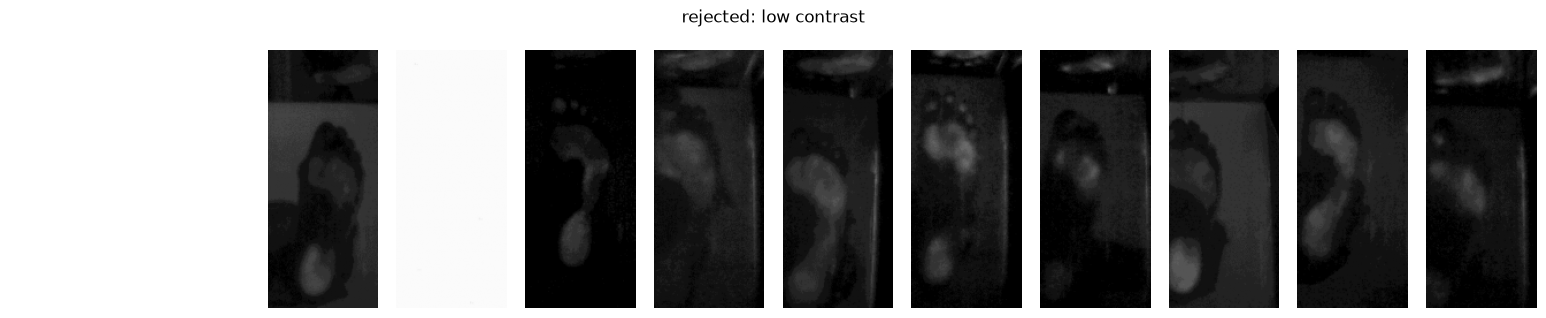

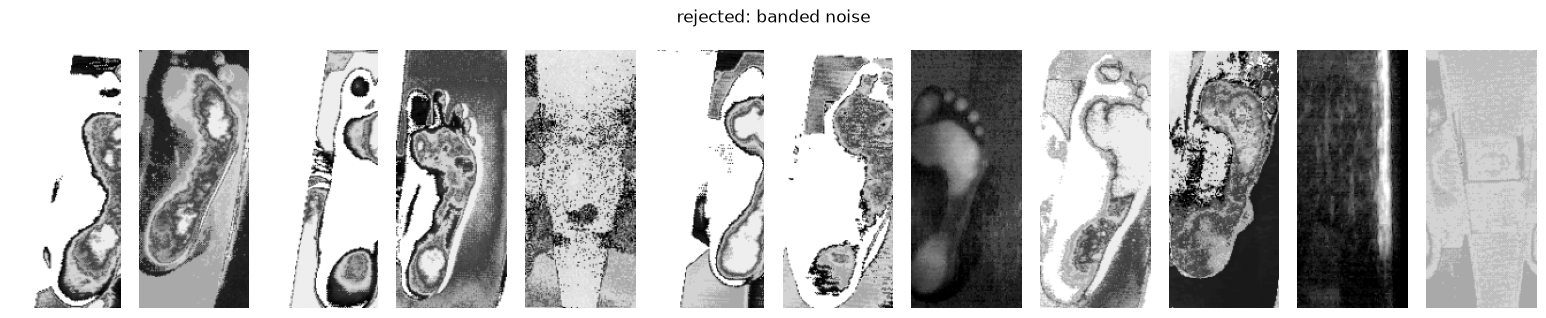

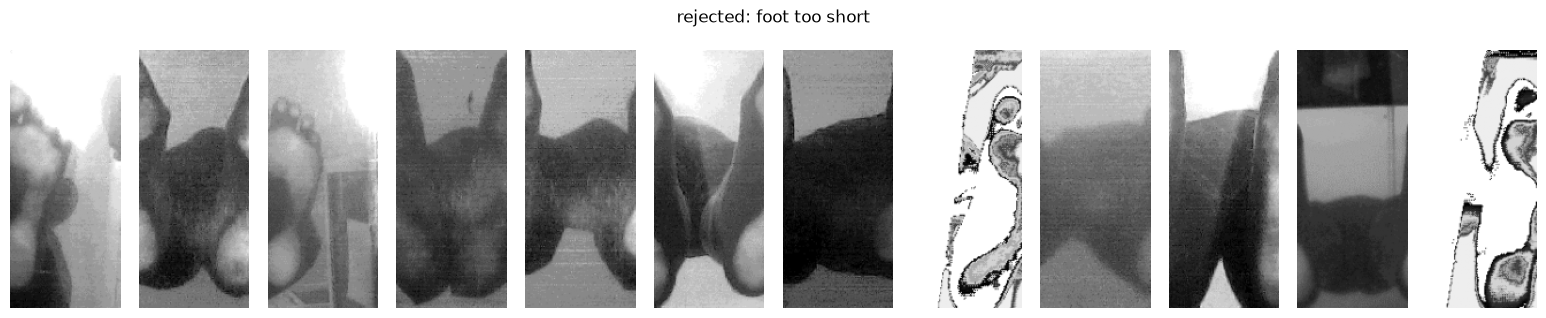

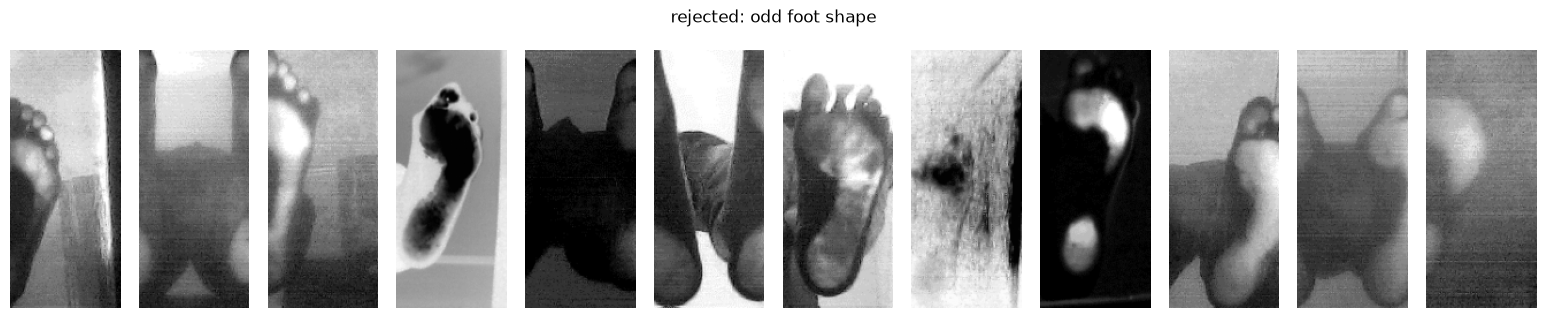

In [8]:
def show_crops(df, title, n=12, seed=0):
    sample = df.sample(min(n, len(df)), random_state=seed)
    fig, axes = plt.subplots(1, len(sample), figsize=(1.3 * len(sample), 3.2))
    for ax, name in zip(np.atleast_1d(axes), sample.foot_file):
        ax.imshow(Image.open(FEET_DIR / name), cmap="gray", vmin=0, vmax=255)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()


show_crops(feet[feet.qc_ok == 1], "random crops that pass QC")
for name, mask in reasons.items():
    if mask.any():
        show_crops(feet[mask], f"rejected: {name}", seed=1)

pixel mean 0.416, std 0.291  (use for input normalisation)


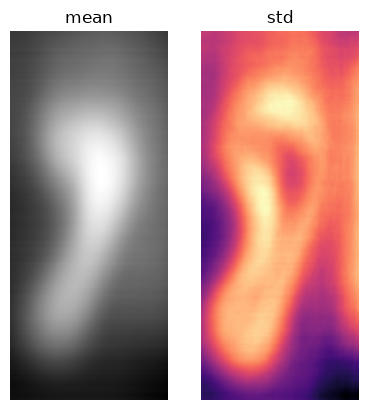

In [9]:
good = feet[feet.qc_ok == 1].sample(min(3000, int(feet.qc_ok.sum())), random_state=0)
stack = np.stack([np.asarray(Image.open(FEET_DIR / f), dtype=np.float32) / 255 for f in good.foot_file])
fig, axes = plt.subplots(1, 2, figsize=(4, 4.2))
axes[0].imshow(stack.mean(0), cmap="gray")
axes[0].set_title("mean")
axes[1].imshow(stack.std(0), cmap="magma")
axes[1].set_title("std")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
print(f"pixel mean {stack.mean():.3f}, std {stack.std():.3f}  (use for input normalisation)")

The mean crop is a clear, centred footprint, so the crops are well aligned. The per-pixel mean and
standard deviation are used to normalise the network input.

## 4. Metadata and labels

43637 image records of 22108 patients


,age,weight_kg,shoe_size
count,42765.0,40034.0,42851.0
mean,44.3,71.3,39.8
std,21.7,20.1,3.2
min,1.0,9.0,16.0
25%,26.0,60.0,38.0
50%,48.0,70.0,39.0
75%,62.0,84.0,42.0
max,100.0,180.0,52.0


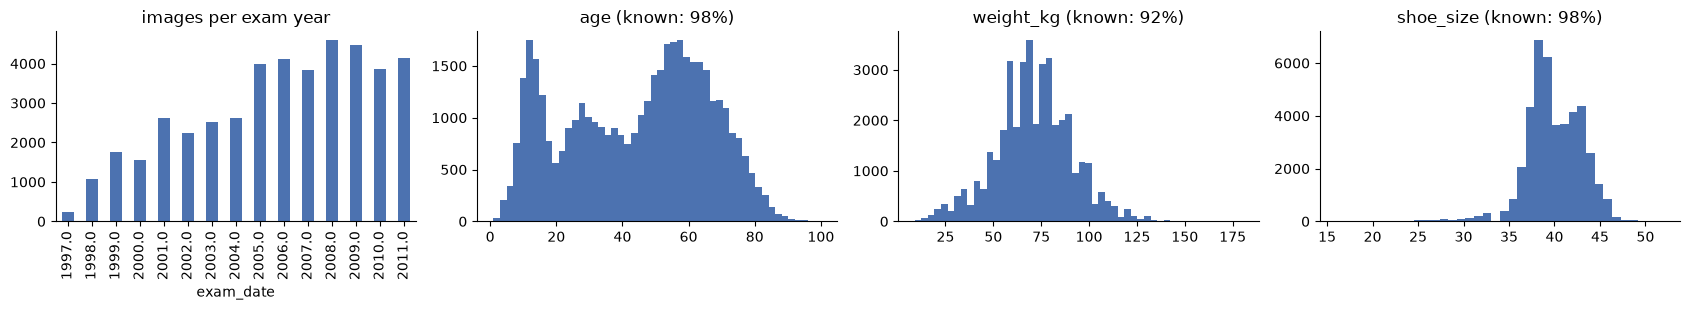

In [10]:
labels = pd.read_csv(DATA_DIR / "labels.csv")
labels["exam_date"] = pd.to_datetime(labels["exam_date"], errors="coerce")
print(f"{len(labels)} image records of {labels.patient_id.nunique()} patients")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
labels["exam_date"].dt.year.value_counts().sort_index().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("images per exam year")
for ax, col, bins in zip(axes[1:], ["age", "weight_kg", "shoe_size"], [50, 50, 38]):
    ax.hist(labels[col].dropna(), bins=bins, color="#4C72B0")
    ax.set_title(f"{col} (known: {labels[col].notna().mean():.0%})")
plt.tight_layout()
labels[["age", "weight_kg", "shoe_size"]].describe().round(1)

In [11]:
per_patient = labels.groupby("patient_id").size()
print(f"images per patient: median {per_patient.median():.0f}, mean {per_patient.mean():.2f}, max {per_patient.max()}")
print(per_patient.clip(upper=10).value_counts().sort_index().rename(index={10: "10+"}).to_string())
labels[["age", "weight_kg", "shoe_size"]].corr().round(2)

images per patient: median 1, mean 1.97, max 49
1      14156
2       3871
3       1500
4        867
5        482
6        327
7        227
8        171
9        118
10+      389


,age,weight_kg,shoe_size
age,1.00,0.43,0.15
weight_kg,0.43,1.00,0.68
shoe_size,0.15,0.68,1.00


Age, weight and shoe size are known for over 90% of the images. They can be used as **regression
targets** or auxiliary tasks. Shoe size is tied to foot length, so it is a good sanity check that the
model really looks at the foot. Most patients have one or two images, but there is a long tail with
many visits, which matters for the split.

images with an e-record note (condition labels defined): 1076 of 43637 (2.5%)


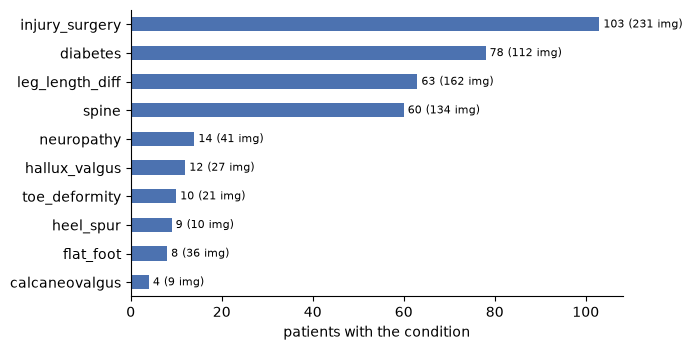

In [12]:
conditions = ["diabetes", "neuropathy", "hallux_valgus", "flat_foot", "calcaneovalgus", "heel_spur",
              "toe_deformity", "spine", "leg_length_diff", "injury_surgery"]
summary = pd.DataFrame({
    "images": [(labels[c] == 1).sum() for c in conditions],
    "patients": [labels.loc[labels[c] == 1, "patient_id"].nunique() for c in conditions],
}, index=conditions).sort_values("patients")
print(f"images with an e-record note (condition labels defined): {labels.has_note.sum()} "
      f"of {len(labels)} ({labels.has_note.mean():.1%})")
ax = summary["patients"].plot.barh(figsize=(7, 3.6), color="#4C72B0")
ax.set_xlabel("patients with the condition")
for i, (n_img, n_pat) in enumerate(zip(summary.images, summary.patients)):
    ax.text(n_pat, i, f" {n_pat} ({n_img} img)", va="center", fontsize=8)
plt.tight_layout()

The condition labels are **too sparse for supervised disease classification**. Most foot-specific
classes (flat foot, hallux valgus, calcaneovalgus, heel spur) have only 4–15 patients. The labels are
also weak: they come from undated, patient-level free-text notes. We have asked the data owner whether
a more detailed diagnosis export exists.

## 5. Train / validation / test split

In [13]:
qc = feet[feet.qc_ok == 1]
leak = qc[qc.split != "unassigned"].groupby("patient_id").split.nunique().max()
assert leak == 1, "a patient appears in more than one split"
qc.groupby("split").agg(crops=("foot_file", "size"), images=("image_file", "nunique"),
                        patients=("patient_id", "nunique"), with_note=("has_note", "sum"),
                        age_mean=("age", "mean"), weight_mean=("weight_kg", "mean"),
                        shoe_mean=("shoe_size", "mean")).round(1)

,crops,images,patients,with_note,age_mean,weight_mean,shoe_mean
split,,,,,,,
test,11428,5951,3094,308.0,43.4,71.4,39.9
train,52846,27504,14416,1343.0,43.9,71.2,39.8
unassigned,1070,556,0,0.0,NaN,NaN,NaN
val,11231,5856,3097,256.0,43.7,71.6,39.9


The split (70 / 15 / 15 %, `preprocess.patient_split`) is grouped by patient, so no person appears in
two subsets. The metadata distributions of the three subsets match. `unassigned` crops come from
images without a database record; they can still be used for unsupervised pre-training. If the final
task uses the rare condition labels, the split should be stratified on them.

## Summary

| Finding | Consequence |
|---|---|
| ~44k footprint images; ~99% are palette BMPs (320×240 / 352×288) | Common decoding + resizing pipeline |
| Palette indices are scrambled; intensity is encoded by a 16-colour false-colour scale | Decode colour → level; never use the index or the RGB rendering directly |
| RGB files (photos, some showing people) and corrupt fragments | Dropped; never published |
| Overexposed, low-contrast and wrongly coloured frames | Removed by QC (about 13% of the foot crops; see section 3) |
| Two feet per image | Split, mirror the left one, 96×224 crop per foot (2 samples per image) |
| Age, weight and shoe size known for >90% of images | Solid supervised targets, usable for pre-training |
| Condition labels for only ~2.5% of images, mostly 4–15 patients per class | Disease classification needs a better label source (asked the data owner) |
| Most patients have 1–2 images, with a long tail | Patient-level split (`data/processed/feet.csv`, column `split`) |